<a href="https://colab.research.google.com/github/sangramshitole07/AML/blob/main/AllRegressionAIML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report,precision_score,recall_score,f1_score,roc_curve,auc,roc_auc_score
)

In [4]:
data={
    "Study_hours":[2,3,4,5,6,7,8,9,1,10,4,7],
    "Attendance":[60,65,70,75,80,85,90,95,55,98,72,88],
    "Assignment_Score":[50,55,58,65,70,74,80,85,45,92,60,78],
    "Final_marks":[48,53,59,64,72,76,83,88,42,95,61,81]
    }
df=pd.DataFrame(data)
display(df.head())
print("shape",df.shape)
print("\n Data type:", df.dtypes)
print("\n Summary:")
display(df.describe())
display("\n Missing Values:")
display(df.isnull().sum())
display("/ Duplicate rows :" ,df.duplicated().sum())


,Study_hours,Attendance,Assignment_Score,Final_marks
0,2,60,50,48
1,3,65,55,53
2,4,70,58,59
3,5,75,65,64
4,6,80,70,72


shape (12, 4)

 Data type: Study_hours         int64
Attendance          int64
Assignment_Score    int64
Final_marks         int64
dtype: object

 Summary:


,Study_hours,Attendance,Assignment_Score,Final_marks
count,12.000000,12.000000,12.000000,12.000000
mean,5.500000,77.750000,67.666667,68.500000
std,2.812311,13.870341,14.593481,16.643317
min,1.000000,55.000000,45.000000,42.000000
25%,3.750000,68.750000,57.250000,57.500000
50%,5.500000,77.500000,67.500000,68.000000
75%,7.250000,88.500000,78.500000,81.500000
max,10.000000,98.000000,92.000000,95.000000


'\n Missing Values:'

,0
Study_hours,0
Attendance,0
Assignment_Score,0
Final_marks,0


'/ Duplicate rows :'

np.int64(0)

In [5]:
"""
from google.colab import files
uploaded=files.upload()
df=pd.read_csv("Student_data.csv)
rest same
"""

'\nfrom google.colab import files\nuploaded=files.upload()\ndf=pd.read_csv("Student_data.csv)\nrest same\n'

In [6]:
target="Final_marks"
X=df[["Study_hours"]]
y=df[target]
print("X Shape :" , X.shape)
print("Y Shape :", y.shape)
display(X.head())
display(y.head())

X Shape : (12, 1)
Y Shape : (12,)


,Study_hours
0,2
1,3
2,4
3,5
4,6


,Final_marks
0,48
1,53
2,59
3,64
4,72


In [7]:
X_train, X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
print("Training Rows :",len(X_train))
print("Testing Rows: ",len(X_test))



Training Rows : 9
Testing Rows:  3


In [8]:

simple_model=LinearRegression()
simple_model.fit(X_train,y_train)
print("Intercept (b0):",simple_model.intercept_)
print("Coefficient (b1)",simple_model.coef_[0])



Intercept (b0): 35.61702127659575
Coefficient (b1) 5.948936170212766


In [9]:
y_pred=simple_model.predict(X_test)
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Residual (actual - predicted)": y_test.to_numpy() - y_pred
})
display(results)

,Actual,Predicted,Residual (actual - predicted)
0,61,59.412766,1.587234
1,95,95.106383,-0.106383
2,48,47.514894,0.485106


In [10]:
new_student=pd.DataFrame({"Study_hours":[6]})
print("Predicted marks for 6 study hours :",
      simple_model.predict(new_student)[0])

Predicted marks for 6 study hours : 71.31063829787234


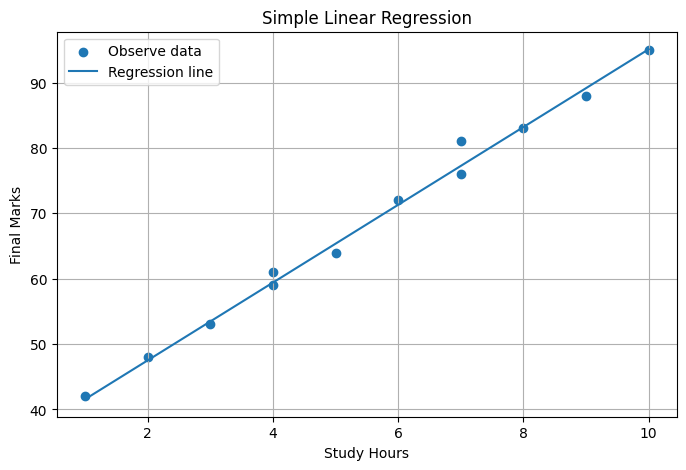

In [11]:
x_line=pd.DataFrame({"Study_hours":np.linspace(df["Study_hours"].max(),df["Study_hours"].min(),100)})
y_line=simple_model.predict(x_line)
plt.figure(figsize=(8,5))
plt.scatter(df["Study_hours"],df["Final_marks"],label="Observe data")
plt.plot(x_line["Study_hours"],y_line,label="Regression line")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid()
plt.show()


In [12]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print("Mean Absolute Error:",mae)
print("Mean Squared Error:",mse)
print("Root Mean Squared Error:",rmse)
print("R2 Score:",r2)

Mean Absolute Error: 0.7262411347517718
Mean Squared Error: 0.9219858156028273
Root Mean Squared Error: 0.960200924600069
R2 Score: 0.9976519885850522


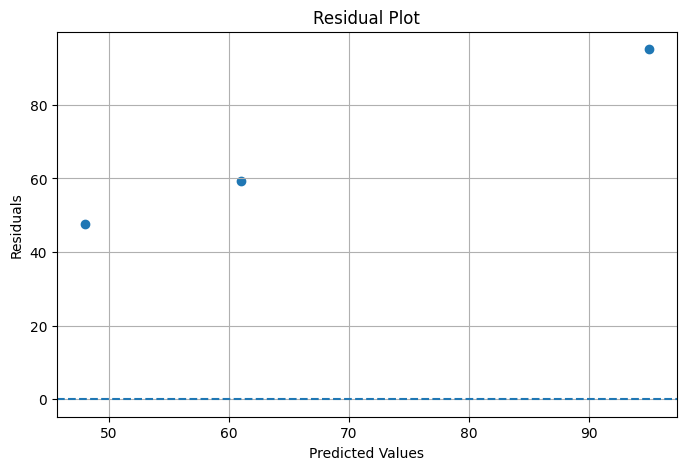

Residual mean : 0.6553191489361604


In [13]:
from matplotlib.lines import lineStyles
residuals=y_test-y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_test,y_pred)
plt.axhline(0,linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid()
plt.show()
print("Residual mean :",residuals.mean())


In [14]:
X_m=df[["Study_hours","Attendance","Assignment_Score"]]
y_m=df[target]

Xm_train,Xm_test,y_m_train,y_m_test=train_test_split(X_m,y_m,test_size=0.20,random_state=42)
multi_model=LinearRegression()
multi_model.fit(Xm_train,y_m_train)
y_m_pred=multi_model.predict(Xm_test)
print("Intercept:",multi_model.intercept_)
coef_table=pd.DataFrame({"Feature":X_m.columns,
                         "Coefficient":multi_model.coef_})
display(coef_table)
#
print("MAE",mean_absolute_error(y_m_test,y_m_pred))
print("MSE",mean_squared_error(y_m_test,y_m_pred))
print("RMSE",np.sqrt(mean_squared_error(y_m_test,y_m_pred)))
print("R2 Score",r2_score(y_m_test,y_m_pred))

print("X Shape :",X_m.shape)
print("Y Shape :",y_m.shape)

Intercept: -34.194010416666615


,Feature,Coefficient
0,Study_hours,-1.401042
1,Attendance,1.231771
2,Assignment_Score,0.212891


MAE 1.3376736111111047
MSE 3.025425663700764
RMSE 1.7393750784982416
R2 Score 0.9922951808224938
X Shape : (12, 3)
Y Shape : (12,)


In [15]:
new_stud=pd.DataFrame({
    "Study_hours":[6],
    "Attendance":[80],
    "Assignment_Score":[72]
})
print("Predicted value :", multi_model.predict(new_stud)[0])

Predicted value : 71.26953125


In [16]:
housing = pd.DataFrame({
    "Size": [800, 1000, 1200, 1500, 1800, 900, 1300, 1600],
    "Location": ["Rural", "Urban", "Rural", "Urban",
                 "Urban", "Rural", "Urban", "Rural"],
    "Price": [30, 50, 42, 72, 85, 35, 61, 66]
})

In [17]:
Xh=housing[["Size","Location"]]
Yh=housing["Price"]

numeric_feature=["Size"]
categorical_feature=["Location"]

preprocessor=ColumnTransformer([
    ("numeric","passthrough",numeric_feature),
    ("categorical",OneHotEncoder(drop="first",handle_unknown="ignore"),
     categorical_feature)
])
house_pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LinearRegression())
])

Xh_train,Xh_test,yh_train,yh_test=train_test_split(
    Xh,Yh,test_size=0.2,random_state=42
)
house_pipeline.fit(Xh_train,yh_train)
yh_pred=house_pipeline.predict(Xh_test)
print("Endcode + regression pipeline MAE:",
      mean_absolute_error(yh_test,yh_pred))

Endcode + regression pipeline MAE: 2.227611940298509


In [18]:
from sklearn.model_selection import cross_val_score, KFold
cv=KFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

cv_score=cross_val_score(
    house_pipeline,
    Xh,
    Yh,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

mae_score=-cv_score
print("Fold MAE", mae_score)
print("mean CV mae",mae_score.mean())
print("standard Deviation:", mae_score.std())

Fold MAE [2.22761194 3.20779221 3.21162281 1.1360424 ]
mean CV mae 2.4457673394837736
standard Deviation: 0.8558895496742714


In [19]:
#l1,l2
ridge_pipeline=Pipeline([
    ("Scale",StandardScaler()),
    ("model",Ridge(alpha=1.0))

])
lasso_pipeline=Pipeline([
    ("Scale",StandardScaler()),
    ("model",Lasso(alpha=0.1,max_iter=10000))
])
ridge_pipeline.fit(Xm_train,y_m_train)
lasso_pipeline.fit(Xm_train,y_m_train)

ridge_pred = ridge_pipeline.predict(Xm_test)
lasso_pred = lasso_pipeline.predict(Xm_test)

print("Ridge test RMSE:",
      np.sqrt(mean_squared_error(y_m_test,ridge_pred))
      )
print("Lasso test RMSE:",
      np.sqrt(mean_squared_error(y_m_test,lasso_pred)))

Ridge test RMSE: 0.8172904914766684
Lasso test RMSE: 1.2884280695527257


In [20]:
ridge_coef = ridge_pipeline.named_steps["model"].coef_
lasso_coef = lasso_pipeline.named_steps["model"].coef_

regularization_table = pd.DataFrame({
    "Feature": X_m.columns,
    "Ordinary Linear": multi_model.coef_,
    "Ridge (scaled inputs)": ridge_coef,
    "Lasso (scaled inputs)": lasso_coef
})
display(regularization_table)

,Feature,Ordinary Linear,Ridge (scaled inputs),Lasso (scaled inputs)
0,Study_hours,-1.401042,4.370346,0.000000
1,Attendance,1.231771,4.765028,11.406963
2,Assignment_Score,0.212891,4.745400,2.889424


In [21]:
from sklearn.model_selection import cross_val_score, KFold

# Define the cross-validation strategy
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 1. Cross-validation for Ridge Pipeline
ridge_cv_scores = cross_val_score(
    ridge_pipeline,
    Xm_train,
    y_m_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)
ridge_rmse_scores = np.sqrt(-ridge_cv_scores)

# 2. Cross-validation for Lasso Pipeline
lasso_cv_scores = cross_val_score(
    lasso_pipeline,
    Xm_train,
    y_m_train,
    cv=cv,
    scoring="neg_mean_squared_error"
)
lasso_rmse_scores = np.sqrt(-lasso_cv_scores)

print("=== Ridge Regression CV (5-Fold) ===")
print("Fold RMSEs:", np.round(ridge_rmse_scores, 4))
print("Mean RMSE:", round(ridge_rmse_scores.mean(), 4))
print("Std Dev:  ", round(ridge_rmse_scores.std(), 4))

print("\n=== Lasso Regression CV (5-Fold) ===")
print("Fold RMSEs:", np.round(lasso_rmse_scores, 4))
print("Mean RMSE:", round(lasso_rmse_scores.mean(), 4))
print("Std Dev:  ", round(lasso_rmse_scores.std(), 4))

=== Ridge Regression CV (5-Fold) ===
Fold RMSEs: [1.2312 0.8584 0.5783 1.9246 0.262 ]
Mean RMSE: 0.9709
Std Dev:   0.5739

=== Lasso Regression CV (5-Fold) ===
Fold RMSEs: [1.1065 1.0769 0.8669 2.6045 0.6053]
Mean RMSE: 1.252
Std Dev:   0.6997


In [28]:
import numpy as np
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define a wide range of alpha values to search over
alphas = np.logspace(-4, 4, 100)

# 1. RidgeCV Pipeline
# Since StandardScaler is in a pipeline, we need to pass alphas specifically to the model
ridge_cv_model = RidgeCV(alphas=alphas, cv=5, scoring="neg_mean_squared_error")
ridge_cv_pipeline = Pipeline([
    ("Scale", StandardScaler()),
    ("model", ridge_cv_model)
])

ridge_cv_pipeline.fit(Xm_train, y_m_train)
best_ridge_alpha = ridge_cv_pipeline.named_steps["model"].alpha_
best_ridge_score = np.sqrt(-ridge_cv_pipeline.named_steps["model"].best_score_)

# 2. LassoCV Pipeline
lasso_cv_model = LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)
lasso_cv_pipeline = Pipeline([
    ("Scale", StandardScaler()),
    ("model", lasso_cv_model)
])

lasso_cv_pipeline.fit(Xm_train, y_m_train)
best_lasso_alpha = lasso_cv_pipeline.named_steps["model"].alpha_
# For LassoCV, MSE path is stored directly; we take the mean MSE across folds for the best alpha
best_lasso_mse = lasso_cv_pipeline.named_steps["model"].mse_path_[np.where(alphas == best_lasso_alpha)[0][0]].mean()
best_lasso_score = np.sqrt(best_lasso_mse)

print("=== RidgeCV Results ===")
print(f"Best Alpha: {best_ridge_alpha:.4f}")
print(f"Best CV RMSE: {best_ridge_score:.4f}")

print("\n=== LassoCV Results ===")
print(f"Best Alpha: {best_lasso_alpha:.4f}")
print(f"Best CV RMSE: {best_lasso_score:.4f}")

=== RidgeCV Results ===
Best Alpha: 0.1707
Best CV RMSE: 1.0901

=== LassoCV Results ===
Best Alpha: 0.0001
Best CV RMSE: 16.3235


In [23]:
classification_data = pd.DataFrame({
    "Study_hours": [1, 2, 2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 7, 8, 5, 2],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 62, 82, 88, 92, 78, 58],
    "Pass": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0]
})

X_class=classification_data[["Study_hours","Attendance"]]
y_class=classification_data["Pass"]

Xcl_train,Xcl_test,ycl_train,ycl_test=train_test_split(
    X_class,y_class,test_size=0.20,random_state=42,
    stratify=y_class
)

log_pipe=Pipeline([
    ("Scale",StandardScaler()),
    ("model",LogisticRegression())
])
log_pipe.fit(Xcl_train,ycl_train)
class_pred = log_pipe.predict(Xcl_test)
class_prob = log_pipe.predict_proba(Xcl_test)[:, 1]
print("Accuracy:",accuracy_score(ycl_test,class_pred))
print("Predicted classes:", class_pred)
print("Probability of Pass:", np.round(class_prob, 3))

Accuracy: 1.0
Predicted classes: [0 1 0 1]
Probability of Pass: [0.278 0.944 0.119 0.987]


In [24]:
print("Accuracy :", accuracy_score(ycl_test, class_pred))
print("Precision:", precision_score(ycl_test, class_pred, zero_division=0))
print("Recall   :", recall_score(ycl_test, class_pred, zero_division=0))
print("F1-score :", f1_score(ycl_test, class_pred, zero_division=0))
print("\nConfusion matrix (rows=actual, columns=predicted):")
print(confusion_matrix(ycl_test, class_pred))
print("\nClassification report:")
print(classification_report(ycl_test, class_pred, zero_division=0))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Confusion matrix (rows=actual, columns=predicted):
[[2 0]
 [0 2]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



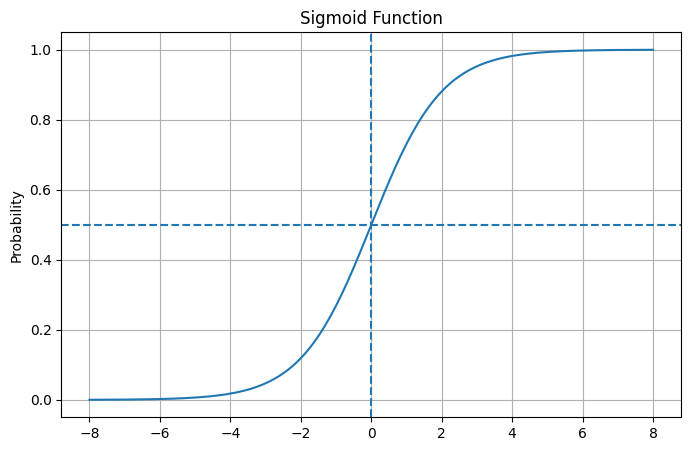

Predicted classes: [0 1 0 1]


In [25]:
z=np.linspace(-8,8,200)
sigmoid=1/(1+np.exp(-z))
plt.figure(figsize=(8,5))
plt.plot(z,sigmoid)
plt.axhline(0.5,linestyle="--")
plt.axvline(0,linestyle="--")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid(True)
plt.show()

threshold=0.5
threshold_pred=(class_prob>=threshold).astype(int)
print("Predicted classes:", threshold_pred)

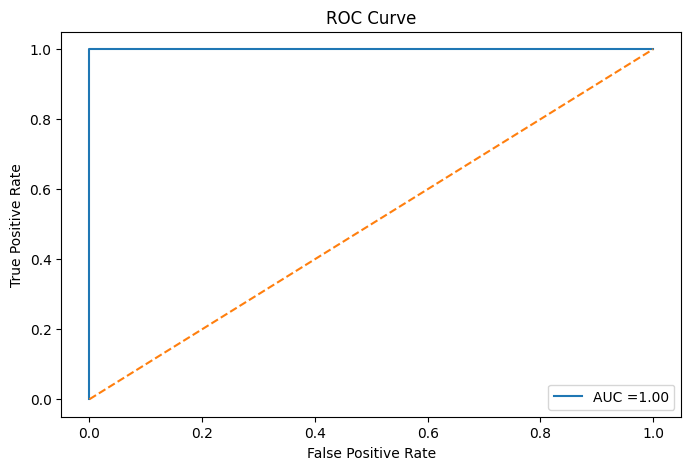

In [26]:
if len(np.unique(y_class))==2:
  fpr,tpr,thresholds=roc_curve(ycl_test,class_prob)
  auc_value=roc_auc_score(ycl_test,class_prob)

  plt.figure(figsize=(8,5))
  plt.plot(fpr,tpr,label=f"AUC ={auc_value:.2f}")
  plt.plot([0,1],[0,1],linestyle="--")
  plt.xlabel("False Positive Rate")
  plt.ylabel("True Positive Rate")
  plt.title("ROC Curve")
  plt.legend()
  plt.grid

In [27]:
from sklearn.model_selection import StratifiedKFold
stratified_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
cv_acc=cross_val_score(
    log_pipe,
    X_class,
    y_class,
    cv=stratified_cv,
    scoring="accuracy"
)
print("fold accuracies :",np.round(cv_acc,3))
print("mean CV accuracy :", cv_acc.mean())

fold accuracies : [1. 1. 1.]
mean CV accuracy : 1.0
